# Week 5 - Support Vector Machines, the Kernel Trick, and SVM Regularization
## Dataset: NOAA Storm Events

This notebook applies support vector machines, the kernel trick, and SVM regularization to the Storm Events data. Week 2 ended with the conclusion that casualty counts cannot predict property damage, and that a better model would need features closer to the physical event, such as event type, location, and timing. This week tests that idea with a classification question that suits SVMs well. Given what kind of event it was, where and when it happened, and how long it lasted, did it cause any reported property damage?

The notebook also ended up covering something I did not plan for. The first version used an ordinary random train/test split, and the tuned SVM kept preferring more and more flexible settings while its test score kept rising. That turned out to be a sign of leakage between related events rather than a better model, and fixing it changes the final numbers quite a bit.

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import (train_test_split, GridSearchCV, validation_curve,
                                     GroupShuffleSplit, GroupKFold)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             roc_auc_score, ConfusionMatrixDisplay)

warnings.filterwarnings('ignore', category=FutureWarning)

df = pd.read_csv('StormEvents_details-ftp_v1.0_d2017_c20260519.csv', low_memory=False)

def parse_damage(val):
    if pd.isna(val):
        return np.nan
    val = str(val).strip().upper()
    mult = {'K': 1e3, 'M': 1e6, 'B': 1e9}
    try:
        return float(val[:-1]) * mult[val[-1]] if val[-1] in mult else float(val)
    except ValueError:
        return np.nan

df['damageProperty'] = df['DAMAGE_PROPERTY'].apply(parse_damage)
print('All 2017 events:', len(df))
print('Events with a reported property damage value:', df['damageProperty'].notna().sum())
print('Events with starting coordinates:', df['BEGIN_LAT'].notna().sum())

All 2017 events: 57041
Events with a reported property damage value: 46451
Events with starting coordinates: 39382


### Target and features

The target is `damaged`, which equals 1 when the event has a property damage estimate above zero. Events with no damage value at all are dropped rather than treated as zero, since a missing estimate is not the same thing as no damage. I also keep only events with starting coordinates. That removes most zone-based events such as winter storms, drought, and heat, which are reported by forecast zone rather than at a point, so the conclusions here apply to point-type events like thunderstorm wind, hail, floods, and tornadoes.

The features are starting latitude and longitude, month, event duration (on a log scale, since it runs from minutes to weeks), and indicator columns for the eight most common event types. Everything is standardized before fitting, because the SVM kernel works on distances between points.

In [2]:
data = df.dropna(subset=['damageProperty', 'BEGIN_LAT', 'BEGIN_LON']).copy()
data['damaged'] = (data['damageProperty'] > 0).astype(int)

begin = pd.to_datetime(data['BEGIN_DATE_TIME'], format='%d-%b-%y %H:%M:%S', errors='coerce')
end = pd.to_datetime(data['END_DATE_TIME'], format='%d-%b-%y %H:%M:%S', errors='coerce')
data['durationHours'] = ((end - begin).dt.total_seconds() / 3600).clip(lower=0)
data['logDuration'] = np.log10(data['durationHours'] + 0.1)
data['month'] = begin.dt.month

top_types = data['EVENT_TYPE'].value_counts().head(8).index
type_cols = []
for t in top_types:
    col = 'type_' + t.replace(' ', '')
    data[col] = (data['EVENT_TYPE'] == t).astype(int)
    type_cols.append(col)

features = ['BEGIN_LAT', 'BEGIN_LON', 'month', 'logDuration'] + type_cols
data = data.dropna(subset=features).reset_index(drop=True)

print('Rows used:', len(data))
print('Share of events with reported property damage:', round(data['damaged'].mean(), 3))
print()
print('Damage rate by event type (top 8 types, everything else is the baseline):')
print(data.groupby('EVENT_TYPE')['damaged'].agg(['mean', 'size'])
          .loc[top_types].rename(columns={'mean': 'share damaged', 'size': 'events'}).round(3))

Rows used: 31863
Share of events with reported property damage: 0.347

Damage rate by event type (top 8 types, everything else is the baseline):
                          share damaged  events
EVENT_TYPE                                     
Thunderstorm Wind                 0.552   12954
Hail                              0.082    7707
Flash Flood                       0.352    3662
Flood                             0.265    2472
Tornado                           0.647    1407
Marine Thunderstorm Wind          0.001    1363
Heavy Rain                        0.062    1250
Lightning                         0.847     354


### How the events are grouped

NOAA logs many separate events for a single storm system. Each one gets its own row, but they share an `EPISODE_ID`, and they are written up by the same National Weather Service forecast office (`WFO`). Before splitting the data, I checked how much events within the same episode, and within the same office, have in common.

Distinct storm episodes: 5220 | average events per episode: 6.1
Episodes with more than one event: 3451
Share of those where every event has the same damage label: 0.644

Weather service offices with 100+ events: 84
Their damage-reporting rates range from 0% to 100% (middle half: 11% to 55%)


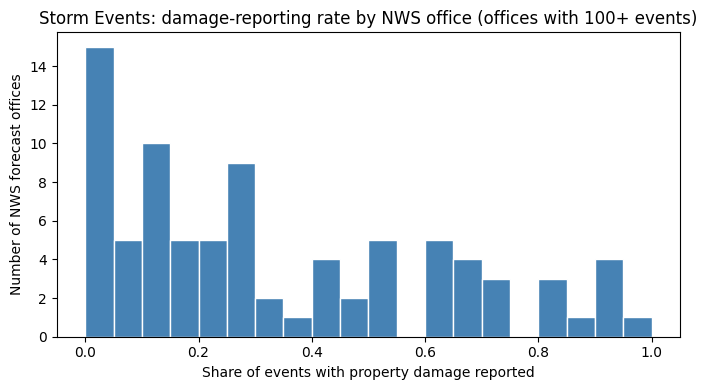

In [3]:
episodes = data.groupby('EPISODE_ID')['damaged'].agg(['mean', 'size'])
multi = episodes[episodes['size'] > 1]
print('Distinct storm episodes:', len(episodes), '| average events per episode:', round(len(data) / len(episodes), 1))
print('Episodes with more than one event:', len(multi))
print('Share of those where every event has the same damage label:',
      round(((multi['mean'] == 0) | (multi['mean'] == 1)).mean(), 3))

wfo = data.groupby('WFO')['damaged'].agg(['mean', 'size'])
wfo = wfo[wfo['size'] >= 100]
print()
print(f'Weather service offices with 100+ events: {len(wfo)}')
print(f"Their damage-reporting rates range from {wfo['mean'].min():.0%} to {wfo['mean'].max():.0%} "
      f"(middle half: {wfo['mean'].quantile(.25):.0%} to {wfo['mean'].quantile(.75):.0%})")

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(wfo['mean'], bins=20, color='steelblue', edgecolor='white')
ax.set_xlabel('Share of events with property damage reported')
ax.set_ylabel('Number of NWS forecast offices')
ax.set_title('Storm Events: damage-reporting rate by NWS office (offices with 100+ events)')
plt.tight_layout()
plt.show()

In [4]:
X = data[features].values
y = data['damaged'].values
groups = data['EPISODE_ID'].values

# Whole episodes go to either train or test, never both.
train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=0).split(X, y, groups))
X_train, X_test, y_train, y_test = X[train_idx], X[test_idx], y[train_idx], y[test_idx]
g_train = groups[train_idx]

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

svm_idx, _ = train_test_split(np.arange(len(y_train)), train_size=8000, stratify=y_train, random_state=0)
X_svm, y_svm, g_svm = X_train_s[svm_idx], y_train[svm_idx], g_train[svm_idx]
print('Full training rows:', len(y_train), '| SVM training sample:', len(y_svm), '| Test rows:', len(y_test))
print('Episodes shared between train and test:', len(set(g_train) & set(groups[test_idx])))

# About a third of events are damaging, so every classifier here reweights the classes.
CLASS_WEIGHT = 'balanced'
CV = GroupKFold(n_splits=3)
CV_GROUPS = g_svm
CLASS_LABELS = ['No damage', 'Damage reported']
TITLE_PREFIX = 'Storm Events'

Full training rows: 23902 | SVM training sample: 8000 | Test rows: 7961
Episodes shared between train and test: 0


### Baselines

Same two reference points as the NFIP notebook. The logistic regression and every SVM below use `class_weight='balanced'`. For an SVM that means the minority class gets a proportionally larger `C`, so misclassifying a damaging event costs more than misclassifying a harmless one.

In [5]:
def evaluate(name, model, X, y):
    pred = model.predict(X)
    score = model.decision_function(X)
    return {'Model': name,
            'Accuracy': accuracy_score(y, pred),
            'Balanced acc.': balanced_accuracy_score(y, pred),
            'F1': f1_score(y, pred),
            'ROC-AUC': roc_auc_score(y, score)}

dummy = DummyClassifier(strategy='most_frequent').fit(X_train_s, y_train)
dummy.decision_function = lambda X: np.zeros(len(X))
logreg = LogisticRegression(max_iter=2000, class_weight='balanced').fit(X_train_s, y_train)
pd.DataFrame([evaluate('Majority class', dummy, X_test_s, y_test),
              evaluate('Logistic regression', logreg, X_test_s, y_test)]).round(3)

,Model,Accuracy,Balanced acc.,F1,ROC-AUC
0,Majority class,0.651,0.500,0.000,0.500
1,Logistic regression,0.708,0.738,0.666,0.823


### The kernel trick in two dimensions

An SVM looks for the boundary with the widest margin between the classes. A linear kernel can only draw a straight line, while the RBF kernel scores similarity by distance, which lets the SVM draw a curved boundary without ever computing a higher-dimensional mapping. Location is a good place to see the difference, since damaging events are not separated from harmless ones by any single straight line across the country. Both models below use latitude and longitude only.

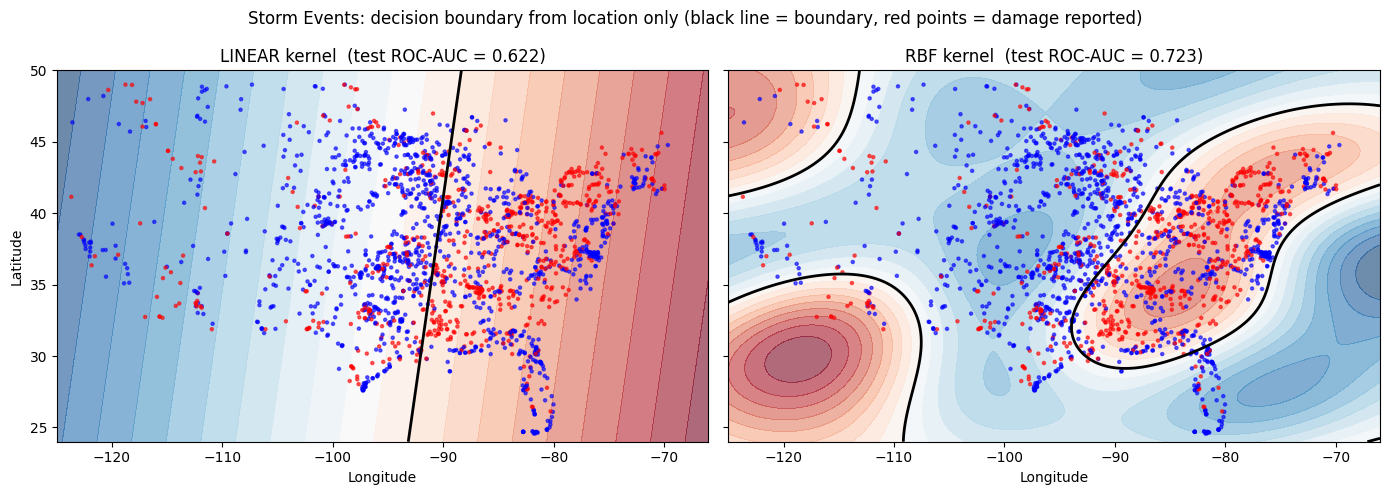

In [6]:
two = ['BEGIN_LON', 'BEGIN_LAT']
Xa = data[two].values
Xa_train, Xa_test = Xa[train_idx], Xa[test_idx]
ya_train, ya_test = y[train_idx], y[test_idx]
fit_idx, _ = train_test_split(np.arange(len(ya_train)), train_size=5000, stratify=ya_train, random_state=0)

x_lo, x_hi = (-125, -66)
y_lo, y_hi = (24, 50)
xx, yy = np.meshgrid(np.linspace(x_lo, x_hi, 300), np.linspace(y_lo, y_hi, 220))
grid_pts = np.c_[xx.ravel(), yy.ravel()]
show = np.random.RandomState(0).choice(len(Xa_test), 2000, replace=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, kernel in zip(axes, ['linear', 'rbf']):
    model = make_pipeline(StandardScaler(), SVC(kernel=kernel, C=1, gamma='scale', class_weight='balanced'))
    model.fit(Xa_train[fit_idx], ya_train[fit_idx])
    auc = roc_auc_score(ya_test, model.decision_function(Xa_test))
    zz = model.decision_function(grid_pts).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=20, cmap='RdBu_r', alpha=0.6)
    ax.contour(xx, yy, zz, levels=[0], colors='black', linewidths=2)
    ax.scatter(Xa_test[show, 0], Xa_test[show, 1], c=ya_test[show], cmap='bwr', s=5, alpha=0.6)
    ax.set_xlim(x_lo, x_hi)
    ax.set_ylim(y_lo, y_hi)
    ax.set_title(f'{kernel.upper()} kernel  (test ROC-AUC = {auc:.3f})')
    ax.set_xlabel('Longitude')
axes[0].set_ylabel('Latitude')
fig.suptitle('Storm Events: decision boundary from location only (black line = boundary, red points = damage reported)')
plt.tight_layout()
plt.show()

### Why the split has to respect storm episodes

The check above showed that events from the same storm usually share the same damage label, and that damage-reporting habits vary widely from one forecast office to the next. With a random split, sibling events from one storm end up on both sides, so a model can score well on a test event by remembering its neighbor from the same storm. An RBF SVM with a large `gamma` is especially good at that kind of memorizing, because each support vector only influences points very close to it.

To measure how much this matters, the plot below fits the same RBF SVM across a range of `gamma` values under two different splits. One is an ordinary random split, and the other keeps every episode entirely in train or entirely in test. The train/test split used for everything in this notebook is the second one.

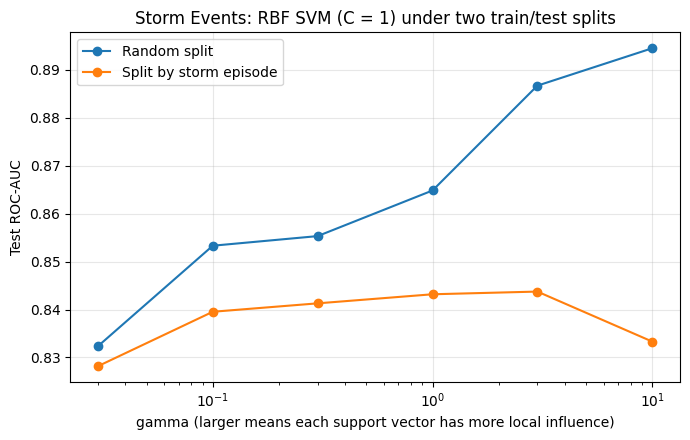

       Random split  Split by storm episode
gamma                                      
0.03          0.832                   0.828
0.10          0.853                   0.840
0.30          0.855                   0.841
1.00          0.865                   0.843
3.00          0.887                   0.844
10.00         0.895                   0.833


In [7]:
# Same RBF settings, same 8,000 training rows' worth of data, two different ways of splitting.
rand_train, rand_test = train_test_split(np.arange(len(y)), test_size=0.25, stratify=y, random_state=0)
gammas = [0.03, 0.1, 0.3, 1, 3, 10]
curves = {}
for label, (tr, te) in {'Random split': (rand_train, rand_test),
                        'Split by storm episode': (train_idx, test_idx)}.items():
    sc = StandardScaler().fit(X[tr])
    Xtr, Xte = sc.transform(X[tr]), sc.transform(X[te])
    sub, _ = train_test_split(np.arange(len(tr)), train_size=8000, stratify=y[tr], random_state=0)
    curves[label] = [roc_auc_score(y[te], SVC(kernel='rbf', C=1, gamma=g, class_weight='balanced')
                                   .fit(Xtr[sub], y[tr][sub]).decision_function(Xte)) for g in gammas]

fig, ax = plt.subplots(figsize=(7, 4.5))
for label, aucs in curves.items():
    ax.semilogx(gammas, aucs, marker='o', label=label)
ax.set_xlabel('gamma (larger means each support vector has more local influence)')
ax.set_ylabel('Test ROC-AUC')
ax.set_title('Storm Events: RBF SVM (C = 1) under two train/test splits')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print(pd.DataFrame(curves, index=gammas).rename_axis('gamma').round(3))

### Tuning the kernel, C, and gamma with grouped cross-validation

Same search as the NFIP notebook, except the cross-validation folds are built with `GroupKFold` on the episode ID, for the reason shown above. `C` sets how heavily the SVM is penalized for margin violations (small `C` is strong regularization), and `gamma` sets how local each RBF support vector's influence is.

In [8]:
# Linear, polynomial, and RBF kernels searched together on the 8,000-row training sample.
# coef0=1 keeps the lower-order terms in the polynomial kernel instead of only the top-degree ones.
param_grid = [
    {'kernel': ['linear'], 'C': [0.01, 0.1, 1, 10]},
    {'kernel': ['poly'], 'degree': [2, 3], 'coef0': [1], 'C': [0.1, 1, 10]},
    {'kernel': ['rbf'], 'C': [0.1, 1, 10, 100], 'gamma': [0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
]
t0 = time.time()
grid = GridSearchCV(SVC(class_weight=CLASS_WEIGHT, cache_size=1000), param_grid,
                    scoring='roc_auc', cv=CV, n_jobs=-1, return_train_score=True)
grid.fit(X_svm, y_svm, groups=CV_GROUPS)
print(f'Grid search took {time.time() - t0:.0f} seconds')

res = pd.DataFrame(grid.cv_results_)
res['kernel'] = res['param_kernel']
best_by_kernel = (res.sort_values('mean_test_score', ascending=False)
                     .groupby('kernel').head(1)
                     [['kernel', 'params', 'mean_train_score', 'mean_test_score']])
print(best_by_kernel.to_string(index=False))
print()
print('Overall best:', grid.best_params_, ' CV ROC-AUC:', round(grid.best_score_, 4))

Grid search took 39 seconds
kernel                                               params  mean_train_score  mean_test_score
   rbf              {'C': 1, 'gamma': 0.3, 'kernel': 'rbf'}          0.877990         0.839200
  poly {'C': 10, 'coef0': 1, 'degree': 3, 'kernel': 'poly'}          0.857827         0.828712
linear                      {'C': 0.01, 'kernel': 'linear'}          0.813737         0.811916

Overall best: {'C': 1, 'gamma': 0.3, 'kernel': 'rbf'}  CV ROC-AUC: 0.8392


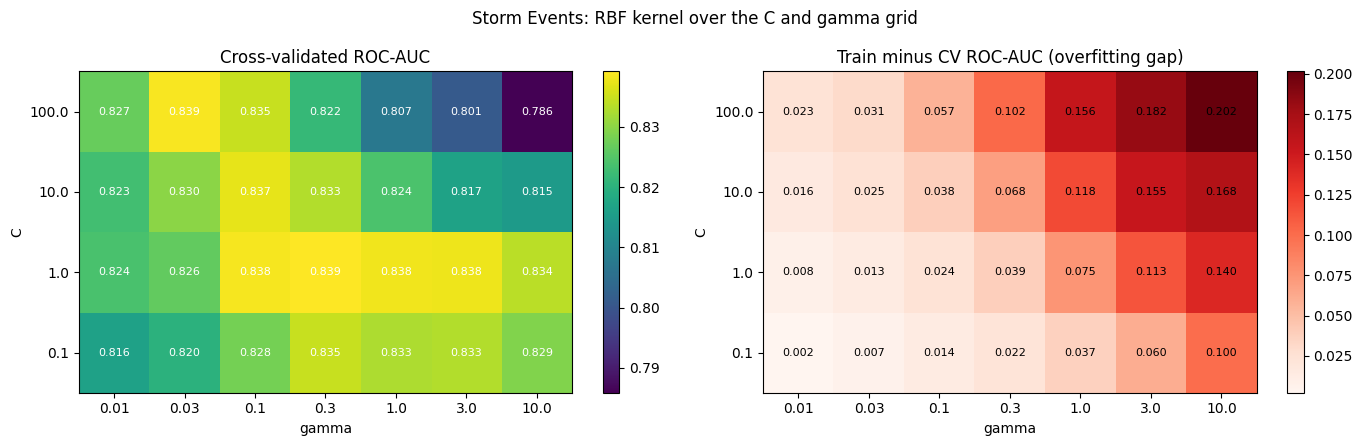

In [9]:
rbf = res[res['kernel'] == 'rbf'].copy()
heat = rbf.pivot_table(index='param_C', columns='param_gamma', values='mean_test_score')
gap = rbf.pivot_table(index='param_C', columns='param_gamma', values='mean_train_score') - heat

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, table, title, cmap in [(axes[0], heat, 'Cross-validated ROC-AUC', 'viridis'),
                               (axes[1], gap, 'Train minus CV ROC-AUC (overfitting gap)', 'Reds')]:
    im = ax.imshow(table.values, cmap=cmap, aspect='auto', origin='lower')
    ax.set_xticks(range(len(table.columns)))
    ax.set_xticklabels(table.columns)
    ax.set_yticks(range(len(table.index)))
    ax.set_yticklabels(table.index)
    ax.set_xlabel('gamma')
    ax.set_ylabel('C')
    ax.set_title(title)
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            ax.text(j, i, f'{table.values[i, j]:.3f}', ha='center', va='center', fontsize=8,
                    color='white' if cmap == 'viridis' else 'black')
    fig.colorbar(im, ax=ax)
fig.suptitle(TITLE_PREFIX + ': RBF kernel over the C and gamma grid')
plt.tight_layout()
plt.show()

Validation curve took 10 seconds


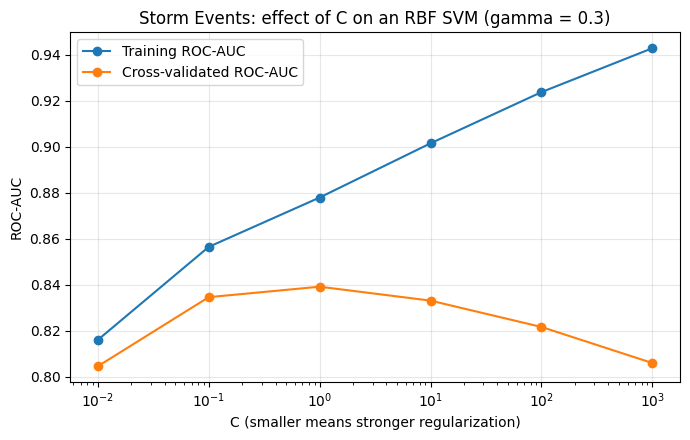

C =    0.01: train 0.816   CV 0.805   gap 0.011
C =     0.1: train 0.857   CV 0.835   gap 0.022
C =       1: train 0.878   CV 0.839   gap 0.039
C =      10: train 0.902   CV 0.833   gap 0.068
C =     100: train 0.924   CV 0.822   gap 0.102
C =    1000: train 0.943   CV 0.806   gap 0.137


In [10]:
best_gamma = grid.best_params_['gamma'] if grid.best_params_['kernel'] == 'rbf' else 0.1
C_range = [0.01, 0.1, 1, 10, 100, 1000]
t0 = time.time()
train_scores, val_scores = validation_curve(
    SVC(kernel='rbf', gamma=best_gamma, class_weight=CLASS_WEIGHT, cache_size=1000),
    X_svm, y_svm, param_name='C', param_range=C_range, groups=CV_GROUPS,
    scoring='roc_auc', cv=CV, n_jobs=-1)
print(f'Validation curve took {time.time() - t0:.0f} seconds')

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.semilogx(C_range, train_scores.mean(axis=1), marker='o', label='Training ROC-AUC')
ax.semilogx(C_range, val_scores.mean(axis=1), marker='o', label='Cross-validated ROC-AUC')
ax.set_xlabel('C (smaller means stronger regularization)')
ax.set_ylabel('ROC-AUC')
ax.set_title(f'{TITLE_PREFIX}: effect of C on an RBF SVM (gamma = {best_gamma})')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

for c, tr, va in zip(C_range, train_scores.mean(axis=1), val_scores.mean(axis=1)):
    print(f'C = {c:>7}: train {tr:.3f}   CV {va:.3f}   gap {tr - va:.3f}')

### Final evaluation on the held-out test set (episodes never seen in training)

In [11]:
best_svm = grid.best_estimator_
best_linear_C = best_by_kernel.loc[best_by_kernel['kernel'] == 'linear', 'params'].iloc[0]['C']
linear_svm = SVC(kernel='linear', C=best_linear_C, class_weight=CLASS_WEIGHT, cache_size=1000).fit(X_svm, y_svm)

results = pd.DataFrame([
    evaluate('Majority class', dummy, X_test_s, y_test),
    evaluate('Logistic regression (all training rows)', logreg, X_test_s, y_test),
    evaluate('Linear SVM (tuned C)', linear_svm, X_test_s, y_test),
    evaluate(f"Best SVM ({grid.best_params_['kernel']} kernel)", best_svm, X_test_s, y_test),
])
print('Held-out test set, n =', len(y_test))
print(results.round(3).to_string(index=False))
print()
print('Support vectors in best SVM:', best_svm.n_support_.sum(), 'of', len(y_svm), 'training rows')

Held-out test set, n = 7961
                                  Model  Accuracy  Balanced acc.    F1  ROC-AUC
                         Majority class     0.651          0.500 0.000    0.500
Logistic regression (all training rows)     0.708          0.738 0.666    0.823
                   Linear SVM (tuned C)     0.708          0.717 0.640    0.804
                  Best SVM (rbf kernel)     0.764          0.771 0.701    0.841

Support vectors in best SVM: 3950 of 8000 training rows


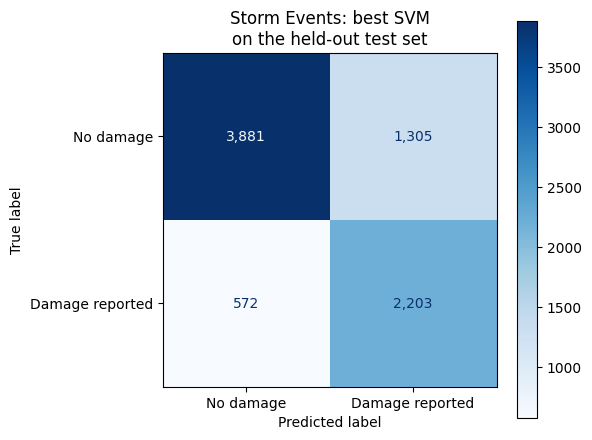

In [12]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_estimator(best_svm, X_test_s, y_test, display_labels=CLASS_LABELS,
                                      cmap='Blues', values_format=',', ax=ax)
ax.set_title(f'{TITLE_PREFIX}: best SVM\non the held-out test set')
plt.tight_layout()
plt.show()

In [13]:
# How much does the 8,000-row cap cost? Refit the best settings on smaller and larger samples.
rows = []
for n in [1000, 2000, 4000, 8000, 16000]:
    idx_n, _ = train_test_split(np.arange(len(y_train)), train_size=n, stratify=y_train, random_state=1)
    m = SVC(class_weight=CLASS_WEIGHT, cache_size=1000, **grid.best_params_)
    t0 = time.time()
    m.fit(X_train_s[idx_n], y_train[idx_n])
    rows.append({'Training rows': n, 'Fit seconds': round(time.time() - t0, 1),
                 'Test ROC-AUC': round(roc_auc_score(y_test, m.decision_function(X_test_s)), 4),
                 'Support vectors': m.n_support_.sum()})
print(pd.DataFrame(rows).to_string(index=False))

 Training rows  Fit seconds  Test ROC-AUC  Support vectors
          1000          0.0        0.8171              602
          2000          0.1        0.8319             1065
          4000          0.3        0.8344             2011
          8000          1.3        0.8392             3810
         16000          5.6        0.8413             7459


### Overfitting

The biggest overfitting risk in this dataset was in the train/test split, not the model settings, and the comparison plot shows it clearly. Under a random split, test ROC-AUC keeps climbing as `gamma` grows, from 0.832 at `gamma = 0.03` to 0.895 at `gamma = 10`, which would suggest the most flexible model is the best one. Under a split that keeps whole storm episodes together, the same models level off around 0.84, and the most flexible one drops to 0.833. That 0.062 difference at `gamma = 10` is the model recognizing sibling events from storms it already saw, not predicting damage for a new storm. My first version of this notebook used a random split and would have reported a test ROC-AUC near 0.89, which turns out to be overstated.

Grouping the split by episode fixed the problem at the test stage, and using `GroupKFold` inside the grid search fixed it during tuning. Without that second step, cross-validation also rewards memorizing, and in my first attempts the tuning pushed `gamma` to the top of whatever grid I gave it (1, then 3, then 10). With grouped folds the best `gamma` landed at 0.3, well inside the grid.

Within the grouped setup, `C` and `gamma` behave the way regularization parameters should. The validation curve shows cross-validated ROC-AUC peaking at `C = 1` (0.839) while the training score keeps rising, and the train minus CV gap grows from 0.011 at `C = 0.01` to 0.137 at `C = 1000`. The heatmap shows the same pattern along the `gamma` axis, with the gap reaching 0.202 at `C = 100` and `gamma = 10`. The final model's test ROC-AUC of 0.841 on episodes it never saw sits right next to its 0.839 cross-validated score, so the tuning itself did not overfit.

### Metrics and hyperparameter tuning

ROC-AUC was the tuning metric because only about a third of events are damaging, and ROC-AUC measures how well the model ranks damaging events above harmless ones without depending on a single cutoff. Accuracy alone would be misleading here, since always predicting no damage already scores 0.651 accuracy with an F1 of zero, so the test results also include balanced accuracy and F1. Every model used `class_weight='balanced'`, which for an SVM raises `C` for the minority class so that missing a damaging event costs almost twice as much as a false alarm.

The grid searched a linear kernel, a polynomial kernel of degree 2 or 3, and an RBF kernel with `C` from 0.1 to 100 and `gamma` from 0.01 to 10, using 3-fold grouped cross-validation on an 8,000-row sample. The RBF kernel won at `C = 1` and `gamma = 0.3` (CV ROC-AUC 0.839), ahead of the cubic polynomial (0.829) and the linear kernel (0.812). The heatmap is fairly flat near the top. Every `gamma` from 0.1 to 3 at `C = 1` scores 0.838 or 0.839, and `C = 100` with `gamma = 0.03` also reaches 0.839, the same diagonal tradeoff between `C` and `gamma` that showed up in the NFIP notebook. A `gamma` of 0.3 sits in the middle of that range, local enough to follow regional differences but not so local that it keys on individual storms.

On the held-out episodes, the tuned RBF SVM reached 0.764 accuracy, 0.771 balanced accuracy, 0.701 F1, and 0.841 ROC-AUC. The confusion matrix shows it catches 2,203 of the 2,775 damaging events (79%), at the cost of 1,305 false alarms among 5,186 harmless ones. For a use like flagging events that probably need a damage survey, that is the direction you would want the errors to lean.

### The 8,000-row sample

Kernel SVM training time grows roughly with the square of the number of rows, so the SVMs were fit on a sample. Doubling from 8,000 to 16,000 rows raised test ROC-AUC from 0.839 to 0.841 while fit time rose from 1.3 to 5.6 seconds, so the sample costs very little. About half of the training events (3,950 of 8,000) end up as support vectors in the tuned model, which says damaging and harmless events overlap a lot in this feature space.

### Expected or unexpected

The better features did what Week 2 suggested they would. Event type, location, month, and duration separate damaging events from harmless ones with a test ROC-AUC of 0.841, a big step up from the casualty-count models in Week 2, although the two are not directly comparable since Week 2 predicted the dollar amount and this notebook predicts whether any damage was reported. The event-type table explains much of the signal on its own. In this data, lightning events report damage 85% of the time and tornadoes 65%, while hail reports damage only 8% of the time and marine thunderstorm wind almost never.

The kernel helped, as expected. With location alone, the linear boundary is one tilted line splitting east from west (ROC-AUC 0.622), and the RBF boundary wraps around a band of damaging events running from the Southeast up through the mid-Atlantic into the Northeast (0.723). The RBF plot also shows the kernel's main weakness. In areas with almost no training data, such as the Pacific off Baja California, it still paints strong colors that come from the shape of the kernel rather than from any real events.

Two results were unexpected. The first is how much the random split overstated performance, covered in the overfitting section above. The second is how inconsistent damage reporting is between forecast offices. Among the 84 offices with at least 100 events, the share of events with damage reported ranges from 0% to 100%, and the middle half of offices falls between 11% and 55%. Some of what the model learns from latitude and longitude is probably which office covers an area and how that office fills in the damage field, rather than anything about the weather. The linear SVM also came in below logistic regression (0.804 against 0.823 ROC-AUC). Both draw a straight boundary, so I think the difference comes from logistic regression seeing three times as many training rows.

### How EDA helped

The EDA mattered more in this notebook than in any earlier one, because it is what caught the leak. The episode check showed that 64% of multi-event episodes have the same damage label for every event, and the office histogram showed how differently offices report damage. Together those two facts predicted that a random split would let the model cheat, and the comparison plot confirmed it. Without that check I would have reported the 0.89 number.

Earlier EDA helped too. The Module B finding that property damage is extremely right-skewed, with most events near zero, is why this notebook predicts whether any damage occurred instead of the dollar amount. The event-type damage rates made it clear that event type would carry much of the signal, and the huge spread in event durations, from minutes to weeks, is why duration is log-scaled.

### External sources

- scikit-learn User Guide, "1.4. Support Vector Machines": https://scikit-learn.org/stable/modules/svm.html
- scikit-learn User Guide, "3.1. Cross-validation: evaluating estimator performance," the section on cross-validation for grouped data (`GroupKFold`, `GroupShuffleSplit`): https://scikit-learn.org/stable/modules/cross_validation.html
- Hsu, Chang, and Lin, "A Practical Guide to Support Vector Classification": https://www.csie.ntu.edu.tw/~cjlin/papers/guide/guide.pdf
- National Weather Service Instruction 10-1605, *Storm Data Preparation*, for how forecast offices enter events, episodes, and damage estimates.

### Conclusions

Once whole storm episodes are kept out of training, a tuned RBF SVM predicts whether a point-type storm event caused property damage with a test ROC-AUC of 0.841, ahead of logistic regression (0.823) and a linear SVM (0.804), and it catches about 79% of damaging events. That supports the Week 2 conclusion that features describing the event itself carry far more information than casualty counts.

The larger lesson here is about evaluation. Storm events are clustered by episode and by reporting office, and a random split rewarded the model for memorizing those clusters, inflating ROC-AUC by as much as 0.06 and steering the tuning toward the most overfit settings. For the Capstone, any model built on Storm Events needs validation grouped by episode, and the damage field should be read partly as a record of how each office reports, not only of what the storm did.